# 05 · BEVFormer (V1 + V2 multi-scale) → triplane (TPV), step by step

**`TRIPLANE_LIFTERS["bevformer"]` → `lifting.triplane.BEVFormerTriplaneLifter`**  ·  Li et al., *BEVFormer* (ECCV 2022) · Simple-BEV `bevformernet.py` / `bevformernet2.py`

> One BEVFormer spatial encoder per plane: learned queries on xy, xz and yz, each owning a line of 3D anchors along its plane normal, read the cameras with deformable spatial cross-attention.

This notebook shows, cell by cell, how the **BEVFormer (V1 + V2 multi-scale)** lifting technique produces a
**tri-perspective view** (three orthogonal feature planes `xy` = BEV, `xz`, `yz`) instead of a single
bird's-eye-view map, *without changing a line of the existing BEV lifter* - the triplane module wraps it
(composition) and only adds what is needed to keep the height axis.

| § | what you will see |
|---|---|
| 1 | the idea, the animated step-by-step GIF and a detailed Mermaid diagram |
| 2 | every animation step as a still image |
| 3 | the shared toy scene (4 cameras, vehicles, pedestrians) |
| 4 | building the triplane lifter from the registry |
| 5 | **inside the lifter**: every intermediate tensor, with exact checks |
| 6 | the triplane contract, verified |
| 7 | end-to-end training on 3D semantic occupancy |
| 8 | the negative control: does it really use the cameras? |
| 9 | how to use it in your own code, recap, cheat sheet, exercises |

## 1. The idea

![BEVFormer (V1 + V2 multi-scale) triplane lifting animation](../../assets/triplane/bevformer.gif)


BEVFormer does not build a voxel volume at all. It owns one **learned query per BEV cell**. Each query has a *pillar*
of `A` 3D anchors at different heights; the anchors are projected into every camera with the calibration
(`Cameras.project`), and **spatial cross-attention** samples a few learned offsets around each projected anchor
(multi-scale deformable attention). An in-plane **deformable self-attention** lets neighbouring queries share context.

Nothing in a BEVFormer layer is specific to the ground plane: self-attention only needs the plane shape and cell
centres, cross-attention only needs projected anchors. So `BEVFormerTriplaneLifter` runs **three** BEVFormer encoders
(`PlaneQueryEncoder`, each a stack of the existing `BEVFormerLayer`):

* `xy` queries own **pillars along z** - exactly `BEVFormerLifter`;
* `xz` queries own **lines along y**; `yz` queries own **lines along x**.

The anchors come from `TPVReferencePoints` (same geometry as TPVFormer). The planes never talk to each other - that is
what TPVFormer adds (notebook 06) - so this is the *independent planes* ablation of TPVFormer.

**BEVFormer V2 (multi-scale)** in this repo is the same lifter reading **two pyramid levels** (`num_levels=2`): a
learned `level_embed` is added per level and the deformable attention samples both scales. §5.4 builds the V2 triplane
and checks that gradients now reach both levels.

### Detailed diagram

Colours: <span style="color:#d48806">■ data</span> · <span style="color:#1f77b4">■ fixed geometry</span>
· <span style="color:#8e44ad">■ learned</span> · <span style="color:#2e8b57">■ reused from the existing BEV lifter</span>
· <span style="color:#c0392b">■ outputs</span>. (Mermaid renders in JupyterLab ≥ 4.1, VS Code and on GitHub;
the matplotlib version below renders everywhere.)

```mermaid
flowchart LR
  IMG["N camera images<br/>(B, N, 3, H, W)"]:::data --> ENC["ImageEncoder<br/>pyramid (B, N, C, H_l, W_l)"]:::learned
  CAM["Cameras<br/>K (B,N,3,3) · cam_to_ego (B,N,4,4)"]:::data
  subgraph REF["TPVReferencePoints (existing)"]
    direction TB
    A1["xy query → pillar of A anchors along z"]:::geo
    A2["xz query → line of A anchors along y"]:::geo
    A3["yz query → line of A anchors along x"]:::geo
  end
  CAM --> PRJ["Cameras.project anchors<br/>→ (u, v) + visibility per camera"]:::geo
  A1 & A2 & A3 --> PRJ
  subgraph ENCS["3 × PlaneQueryEncoder (new) · each = stack of BEVFormerLayer (existing)"]
    direction TB
    Q["learned queries H·W per plane"]:::learned --> SA["deformable self-attention<br/>inside the plane"]:::learned
    SA --> SCA["spatial cross-attention<br/>deformable reads at projected anchors"]:::learned
    SCA --> FF["feed-forward"]:::learned
    FF -->|"× num_layers"| SA
  end
  ENC --> SCA
  PRJ --> SCA
  FF --> PP["PlaneProjection<br/>1×1 conv per plane"]:::learned
  PP --> TPV
  TPV["TPVPlanes<br/>xy (B,C,X,Y) · xz (B,C,X,Z) · yz (B,C,Y,Z)"]:::out
  TPV --> BEVH["TriplaneBEVHead<br/>f = xy + xz + yz → fold Z<br/>BEV (B, C, X, Y)"]:::learned
  TPV --> AGG["TPVAggregator<br/>voxel logits (B,K,X,Y,Z)<br/>+ point logits (B,K,P)"]:::learned
  classDef data fill:#fff7e6,stroke:#d48806,color:#222
  classDef geo fill:#eaf2fb,stroke:#1f77b4,color:#222
  classDef learned fill:#f1e6f8,stroke:#8e44ad,color:#222
  classDef reused fill:#eaf7ea,stroke:#2e8b57,color:#222
  classDef out fill:#fdecea,stroke:#c0392b,color:#222
```

### Shapes and equations


For a query $q$ on plane $P$ with anchors $\{a_{q,k}\}_{k=1..A}$ along the plane normal:

$$ \mathrm{SCA}(q) = \frac{1}{|\mathcal V_q|} \sum_{n \in \mathcal V_q} \sum_{k=1}^{A} \mathrm{MSDeformAttn}\big(q,\ \pi_n(a_{q,k}),\ F_n\big),
\qquad \mathcal V_q = \{ n : \exists k,\ \pi_n(a_{q,k}) \text{ visible} \} $$

$$ q \leftarrow \mathrm{FFN}\Big(\mathrm{SCA}\big(\mathrm{DeformSelfAttn}_P(q)\big)\Big) \quad (\times\ \text{num\_layers}) $$

| tensor | shape |
|---|---|
| queries per plane | `xy: X·Y`, `xz: X·Z`, `yz: Y·Z` (each `C` wide) |
| anchors per plane | `(Q_P, A_P, 3)` with `A = (4, 8, 8)` by default |
| projected anchors | `(B, N, Q_P, A_P, 2)` in `[0, 1]` + visibility `(B, N, Q_P, A_P)` |
| pyramid values | `(B, N, S, C)`, `S = Σ_l H_l W_l` |

In [1]:
import os, sys, time, warnings
warnings.filterwarnings("ignore")

# tpv_kit lives next to this notebook; also works when Jupyter starts at the repo root.
for _p in (".", os.path.join("notebooks", "triplane")):
    if os.path.isdir(os.path.join(_p, "tpv_kit")):
        sys.path.insert(0, os.path.abspath(_p)); break

import numpy as np
import torch, torch.nn.functional as F
import matplotlib.pyplot as plt

from lifting import BaseLifter
from lifting.encoders import SimpleConvEncoder
from lifting.lifters import LIFTERS
from lifting.triplane import TRIPLANE_LIFTERS, build_triplane_lifter, build_triplane_model, build_triplane_bev_model
from tpv_kit import (TriplaneScene, PlanePlotter, PipelineDiagram, StoryboardViewer,
                     TriplaneContractChecker, OccupancyExperiment, ExperimentResult)

torch.manual_seed(0)
torch.set_num_threads(min(4, torch.get_num_threads()))
plt.rcParams.update({"figure.dpi": 100, "image.interpolation": "nearest"})
plotter = PlanePlotter()
print("torch", torch.__version__, "| triplane lifters:", TRIPLANE_LIFTERS.names())

torch 2.14.1 | triplane lifters: ['alpamayo', 'bev_adapter', 'bevformer', 'depth_warp', 'lift_splat', 'mlp_view', 'simple_bev', 'tiim', 'tpvformer']


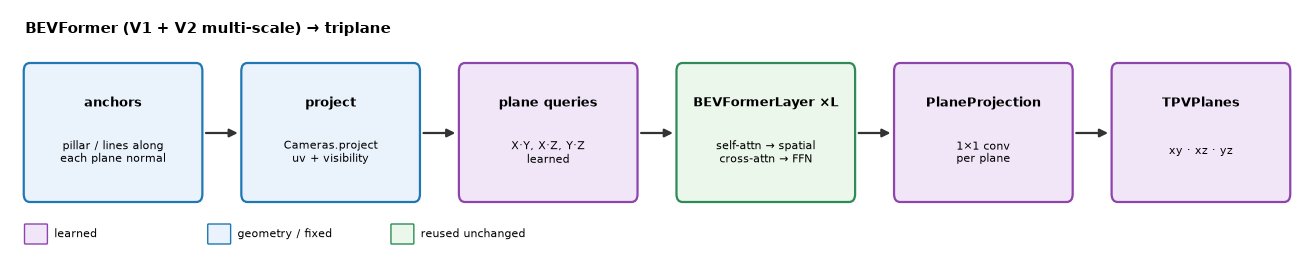

In [2]:
PipelineDiagram('BEVFormer (V1 + V2 multi-scale) → triplane').extend([
    ('anchors', 'pillar / lines along\neach plane normal', 'geometry'),
    ('project', 'Cameras.project\nuv + visibility', 'geometry'),
    ('plane queries', 'X·Y, X·Z, Y·Z\nlearned', 'learned'),
    ('BEVFormerLayer ×L', 'self-attn → spatial\ncross-attn → FFN', 'reused'),
    ('PlaneProjection', '1×1 conv\nper plane', 'learned'),
    ('TPVPlanes', 'xy · xz · yz', 'learned'),
]).show()

## 2. The animation, one still per step

The GIF above is rendered by `lifting.triplane.animation` (Pillow only, exact geometry on a toy scene:
4 cameras at the origin, a car, a pedestrian and a pole). `StoryboardViewer` re-renders the **final frame of every
step** so the whole sequence can be read at once. Regenerate all GIFs with `python scripts/make_triplane_gifs.py`.

step 1: Inputs
step 2: Learned plane queries
step 3: 3D anchors along each plane normal
step 4: Project anchors -> reference points
step 5: Deformable attention (in-plane + image)
step 6: Stack layers -> planes
step 7: Triplane output


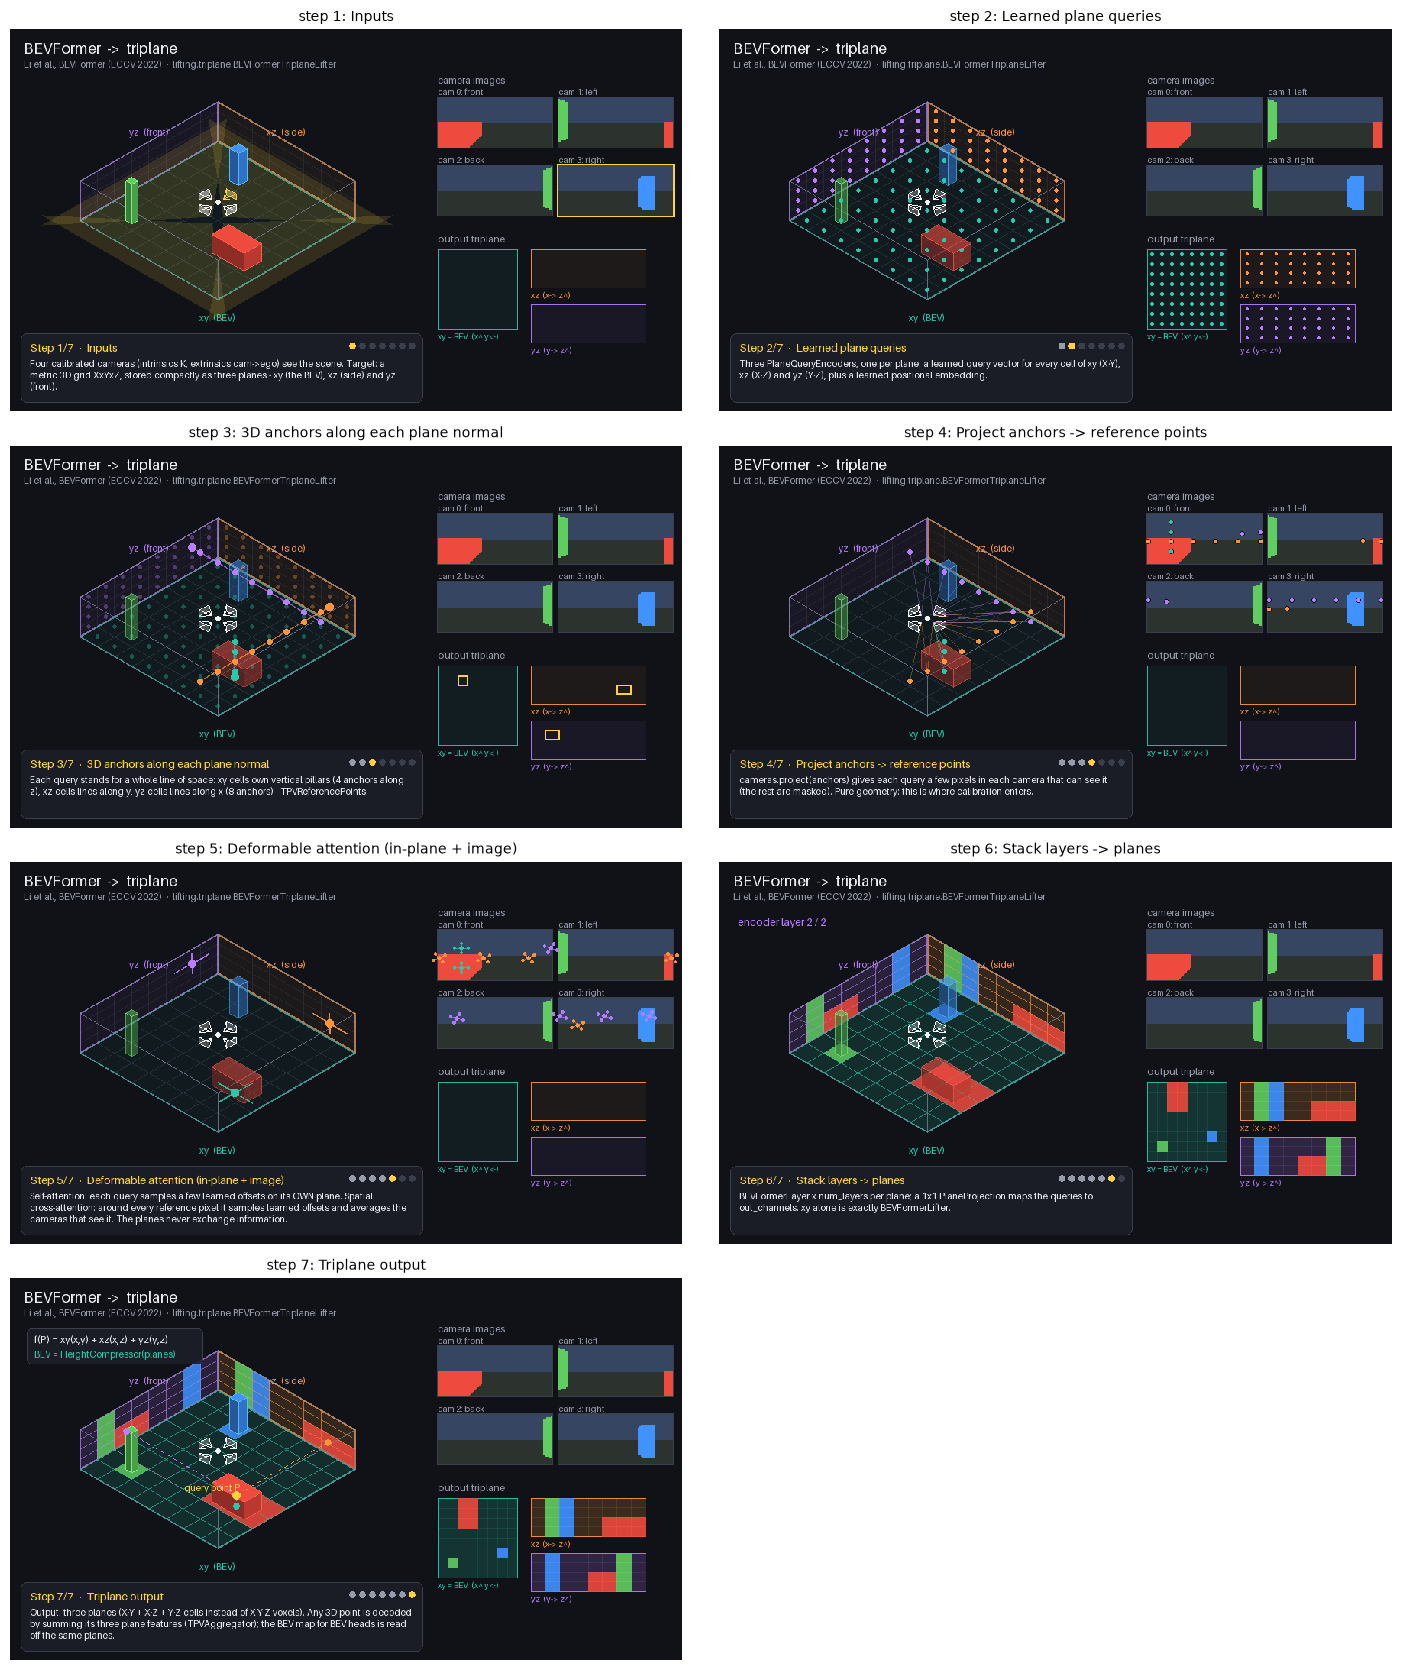

In [3]:
viewer = StoryboardViewer("bevformer")
for i, title in enumerate(viewer.step_titles(), 1):
    print(f"step {i}: {title}")
viewer.contact_sheet()

## 3. The scene

Every triplane notebook uses the same `TriplaneScene`: a `32 m × 32 m × 4 m` region cut into `16 × 16 × 4`
cells, four `48 × 96` cameras whose yaw is **randomly rotated per scene** (so no network can memorise where
"front" is - it must read the calibration), and procedurally placed vehicles (red) and pedestrians (blue).
The ground truth is a 3D occupancy grid `(B, X, Y, Z)`; collapsing it along each axis gives the three
**label planes** each triplane is supervised against.

grid      : x (-16.0, 16.0) y (-16.0, 16.0) z (-1.0, 3.0) m, resolution (16, 16, 4)
voxel     : (2.0, 2.0, 1.0) m
cameras   : 4 x (48, 96) px
scenes    : 128 train / 32 test (batch 4)
TPV cells : xy 256 + xz 64 + yz 64 = 384  (voxels: 1024)


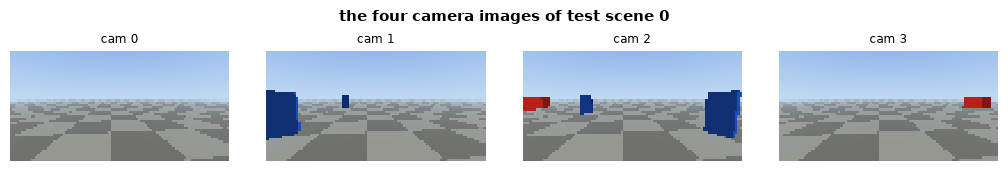

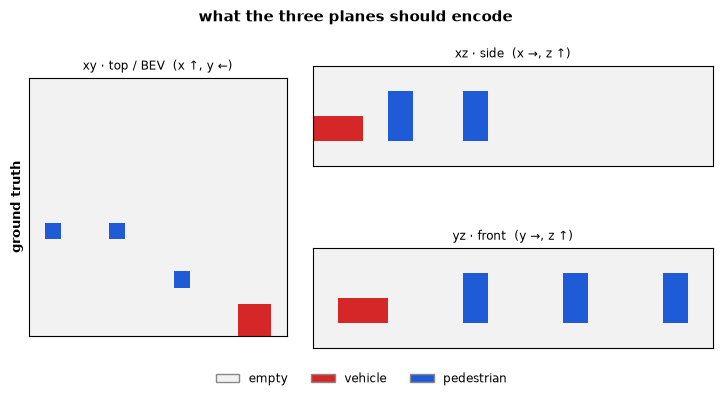

In [4]:
scene = TriplaneScene()
print(scene.describe())
batch = scene.sample
plotter.cameras(batch.images, title="the four camera images of test scene 0")
plotter.labels([("ground truth", scene.label_planes(batch.occupancy))], title="what the three planes should encode")

## 4. Build the triplane lifter

Two equivalent ways:

* `TRIPLANE_LIFTERS.build("bevformer", grid=..., in_channels=..., out_channels=...)` - the raw registry;
* `build_triplane_lifter("bevformer", grid, channels, image_size, num_cameras, encoder)` - also injects the
  context some lifters need (`feature_size`, `num_cameras`, `depth_bins`), exactly like `lifting.models.build_lifter`
  does for BEV lifters.

The image encoder turns `(B·N, 3, H, W)` images into a feature pyramid (strides 4 and 8 here); every lifter
consumes `(B, N, C, H_l, W_l)` per level.

In [5]:
C = 32
encoder = SimpleConvEncoder(out_channels=C, num_levels=2)
features = scene.encode(encoder, batch)
cameras = batch.cameras
print("feature pyramid:", [tuple(f.shape) for f in features])

lifter = build_triplane_lifter("bevformer", scene.grid, C, scene.image_size, scene.num_cameras, encoder, num_layers=1)
print(type(lifter).__name__, "| is a BaseLifter too:", isinstance(lifter, BaseLifter))
print(f"parameters: {sum(p.numel() for p in lifter.parameters()):,}")
for name, child in lifter.named_children():
    n = sum(p.numel() for p in child.parameters())
    print(f"  .{name:<12s} {type(child).__name__:<28s} {n:>9,} params")

feature pyramid: [(4, 4, 32, 12, 24), (4, 4, 32, 6, 12)]
BEVFormerTriplaneLifter | is a BaseLifter too: True
parameters: 112,176
  .bev_head     TriplaneBEVHead                 37,984 params
  .encoders     ModuleList                      70,992 params
  .projection   PlaneProjection                  3,168 params


## 5. Inside the lifter, step by step

### 5.1 Anchors: a pillar or a line per query

`lifter.references` is a `TPVReferencePoints`. For each plane it places `A` anchors along the axis the plane does
**not** contain. Below: the anchors of one query of each plane, seen from above.

In [6]:
REFS = lifter.references
print(type(REFS).__name__, '| anchors per plane:', REFS.num_anchors, '| plane shapes:', REFS.plane_shapes)

TPVReferencePoints | anchors per plane: (4, 8, 8) | plane shapes: [(16, 16), (16, 4), (16, 4)]


plane xy: anchors (256, 4, 3)  one query: [[1.0, -9.0, -0.5], [1.0, -9.0, 0.5], [1.0, -9.0, 1.5], [1.0, -9.0, 2.5]]
plane xz: anchors (64, 8, 3)  one query: [[1.0, -14.0, 2.5], [1.0, -10.0, 2.5], [1.0, -6.0, 2.5], [1.0, -2.0, 2.5], [1.0, 2.0, 2.5], [1.0, 6.0, 2.5], [1.0, 10.0, 2.5], [1.0, 14.0, 2.5]]
plane yz: anchors (64, 8, 3)  one query: [[-14.0, 1.0, 2.5], [-10.0, 1.0, 2.5], [-6.0, 1.0, 2.5], [-2.0, 1.0, 2.5], [2.0, 1.0, 2.5], [6.0, 1.0, 2.5], [10.0, 1.0, 2.5], [14.0, 1.0, 2.5]]


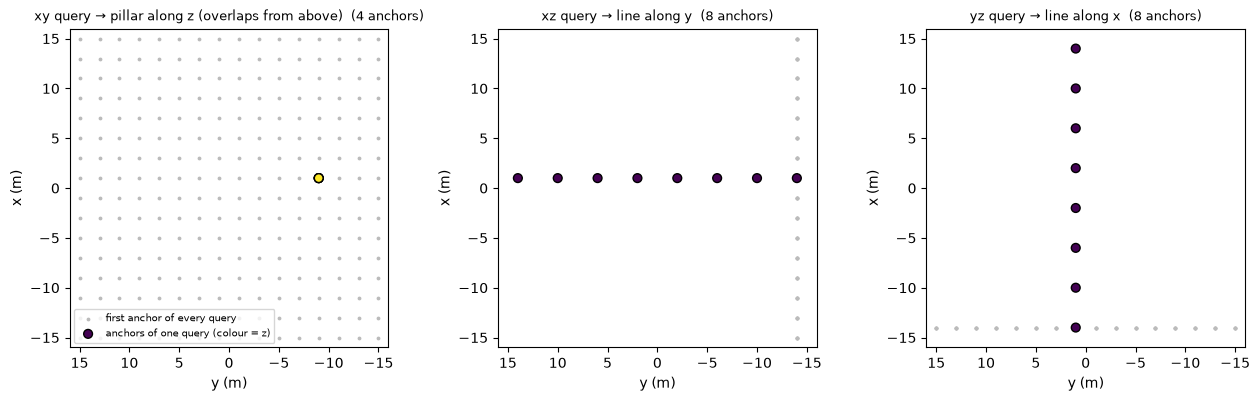

In [7]:
# Where are the 3D anchors of one query on each plane? (top view of the grid, metres)
refs = REFS
fig, axes = plt.subplots(1, 3, figsize=(13, 4), facecolor="white")
names = ["xy query → pillar along z (overlaps from above)", "xz query → line along y", "yz query → line along x"]
g = scene.grid
for plane, ax in enumerate(axes):
    anchors = refs.anchor_points(plane)                    # (Q_plane, A, 3)
    q = anchors.shape[0] // 2 + 3                          # some query near the middle
    allc = anchors[:, 0]
    ax.scatter(allc[:, 1], allc[:, 0], s=3, color="#bbbbbb", label="first anchor of every query")
    ax.scatter(anchors[q, :, 1], anchors[q, :, 0], s=40, c=anchors[q, :, 2], cmap="viridis", edgecolor="k", zorder=3,
               label="anchors of one query (colour = z)")
    ax.set_xlim(g.y_bounds[1], g.y_bounds[0]); ax.set_ylim(*g.x_bounds); ax.set_aspect("equal")
    ax.set_xlabel("y (m)"); ax.set_ylabel("x (m)"); ax.set_title(f"{names[plane]}  ({anchors.shape[1]} anchors)", fontsize=9.5)
    print(f"plane {'xy xz yz'.split()[plane]}: anchors {tuple(anchors.shape)}  one query: {anchors[q].round(decimals=1).tolist()}")
axes[0].legend(fontsize=7, loc="lower left")
plt.tight_layout(); plt.show()

### 5.2 Project the anchors into every camera

Cross-attention only ever reads image features at (offsets around) these projected anchors; a query whose anchors are
invisible in every camera receives nothing from the images - only from its neighbours through self-attention.

plane xy: projected anchors (4, 4, 256, 4, 2)  visible (4, 4, 256, 4)
plane xz: projected anchors (4, 4, 64, 8, 2)  visible (4, 4, 64, 8)
plane yz: projected anchors (4, 4, 64, 8, 2)  visible (4, 4, 64, 8)


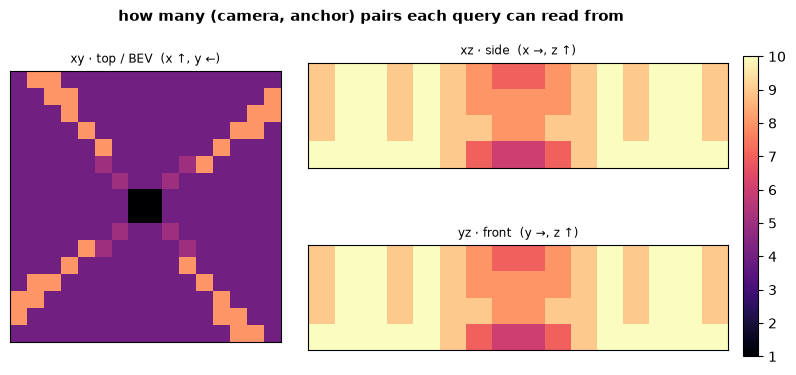

In [8]:
# Which plane cells see at least one anchor in at least one camera? (scene 0)
camera_reference = REFS.camera_reference_points(cameras)  # per plane: (B,N,Q,A,2) uv in [0,1], (B,N,Q,A) visible
seen = []
for plane, ((ref, vis), (h, w)) in enumerate(zip(camera_reference, REFS.plane_shapes)):
    print(f"plane {'xy xz yz'.split()[plane]}: projected anchors {tuple(ref.shape)}  visible {tuple(vis.shape)}")
    seen.append(vis[0].float().sum((0, 2)).view(h, w))    # (camera, anchor) hits per query
plotter.scalar_planes(seen, "how many (camera, anchor) pairs each query can read from", cmap="magma")

### 5.3 Three independent BEVFormer encoders

Each `PlaneQueryEncoder` owns its queries, positional embeddings and `num_layers` × `BEVFormerLayer` - the **same
class** `BEVFormerLifter` uses. The flattened pyramid (`flatten_pyramid`) is shared by the three encoders.

In [9]:
from lifting.lifters.bevformer.bevformer_layer import BEVFormerLayer
from lifting.lifters.pyramid import flatten_pyramid
for name, enc in zip(("xy", "xz", "yz"), lifter.encoders):
    layer = enc.layers[0]
    print(f"{name}: plane {enc.plane_shape}  queries {tuple(enc.queries.shape)}  layers {len(enc.layers)} x "
          f"{type(layer).__name__} (existing class: {isinstance(layer, BEVFormerLayer)})  "
          f"params {sum(p.numel() for p in enc.parameters()):,}")

values, shapes = flatten_pyramid(features[: lifter.num_levels], lifter.level_embed)
print("flattened pyramid:", tuple(values.shape), "levels", shapes)
with torch.no_grad():
    raw = [enc(values, shapes, ref, vis) for enc, (ref, vis) in zip(lifter.encoders, REFS.camera_reference_points(cameras))]
print("raw plane outputs (before PlaneProjection):", [tuple(p.shape) for p in raw])

xy: plane (16, 16)  queries (256, 32)  layers 1 x BEVFormerLayer (existing class: True)  params 29,744
xz: plane (16, 4)  queries (64, 32)  layers 1 x BEVFormerLayer (existing class: True)  params 20,624
yz: plane (16, 4)  queries (64, 32)  layers 1 x BEVFormerLayer (existing class: True)  params 20,624
flattened pyramid: (4, 4, 288, 32) levels [(12, 24)]
raw plane outputs (before PlaneProjection): [(4, 32, 16, 16), (4, 32, 16, 4), (4, 32, 16, 4)]


### 5.4 BEVFormer V2: the multi-scale triplane

Same class, `num_levels=2`. The contract checker now reports gradients reaching **both** pyramid levels.

In [10]:
lifter_v2 = build_triplane_lifter("bevformer", scene.grid, C, scene.image_size, scene.num_cameras, encoder,
                                  num_layers=1, num_levels=2)
print("level_embed:", tuple(lifter_v2.level_embed.shape), "| extra parameters vs V1:",
      sum(p.numel() for p in lifter_v2.parameters()) - sum(p.numel() for p in lifter.parameters()))
assert TriplaneContractChecker(lifter_v2, features, cameras).run()

level_embed: (2, 32) | extra parameters vs V1: 15872


PASS  plane shapes            xy(4, 32, 16, 16) xz(4, 32, 16, 4) yz(4, 32, 16, 4)
PASS  BEV = bev_head(planes)  BEV (4, 32, 16, 16), max |diff| = 0.0e+00
PASS  f = xy + xz + yz        voxel (8,8,2) max |diff| = 0.0e+00
PASS  reuses BEV lifter       native triplane lifter built from existing layers (BEVFormerTriplaneLifter)
PASS  gradients reach images  2/2 pyramid levels receive gradient


## 6. The triplane contract, verified

Every triplane lifter promises the same five properties (Liskov: it is still a `BaseLifter`, so it drops into
`BEVSegmentationModel`, the trainer and the verifier unchanged). `TriplaneContractChecker` runs them on real tensors.

PASS  plane shapes            xy(4, 32, 16, 16) xz(4, 32, 16, 4) yz(4, 32, 16, 4)
PASS  BEV = bev_head(planes)  BEV (4, 32, 16, 16), max |diff| = 0.0e+00
PASS  f = xy + xz + yz        voxel (8,8,2) max |diff| = 0.0e+00
PASS  reuses BEV lifter       native triplane lifter built from existing layers (BEVFormerTriplaneLifter)
PASS  gradients reach images  1/2 pyramid levels receive gradient


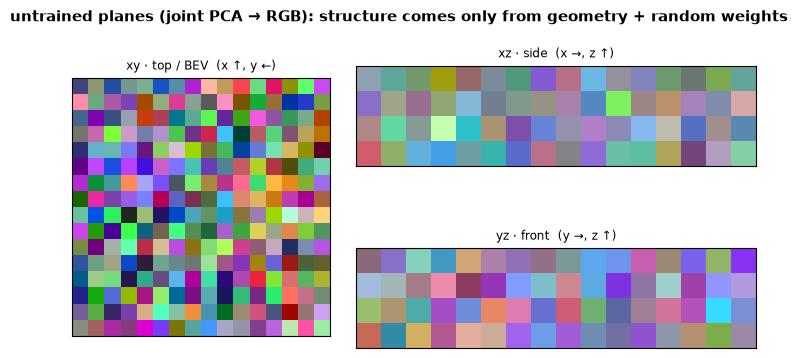

In [11]:
assert TriplaneContractChecker(lifter, features, cameras).run()
with torch.no_grad():
    planes = lifter.lift_planes(features, cameras)
plotter.features(planes, title="untrained planes (joint PCA → RGB): structure comes only from geometry + random weights")

## 7. Train end to end on 3D semantic occupancy

`build_triplane_model("bevformer", ...)` = encoder → **this triplane lifter** → `TPVAggregator` (an MLP on
`f(x,y,z) = xy + xz + yz`), plus one auxiliary classifier per plane. `OccupancyTask(aux_weight=0.5)` adds a
cross-entropy on each plane against the collapsed labels of §3. 150 AdamW steps on 128 scenes, CPU only.

lifter          params    time   before    after  corrupted   verdict
bevformer         249k    5.1s    0.008    0.295      0.030   uses geometry


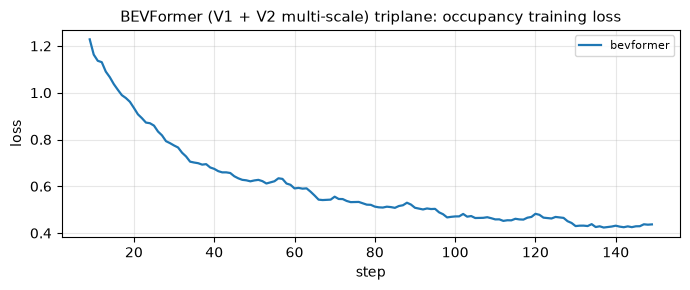

In [12]:
exp = OccupancyExperiment(scene, "bevformer", num_layers=1)
result = exp.run(steps=150)
print(ExperimentResult.header()); print(result.row())
OccupancyExperiment.plot_losses([result], title="BEVFormer (V1 + V2 multi-scale) triplane: occupancy training loss")

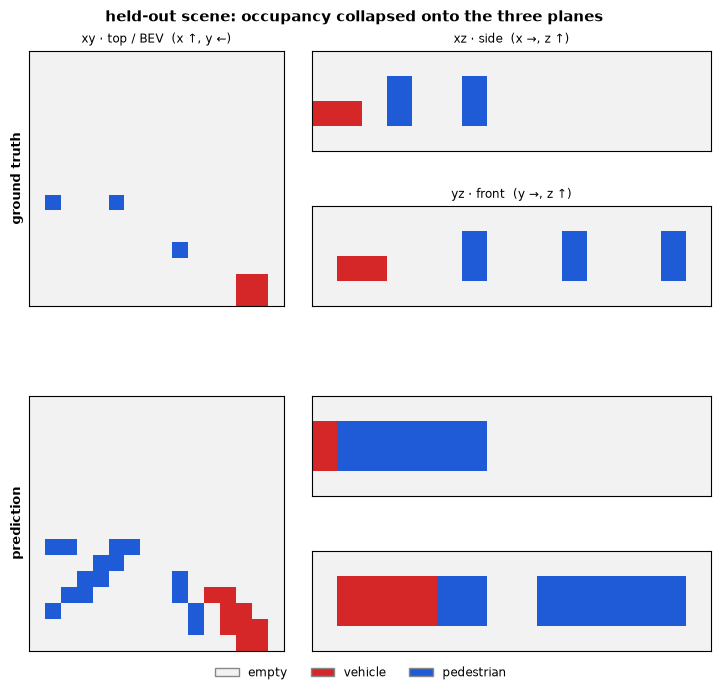

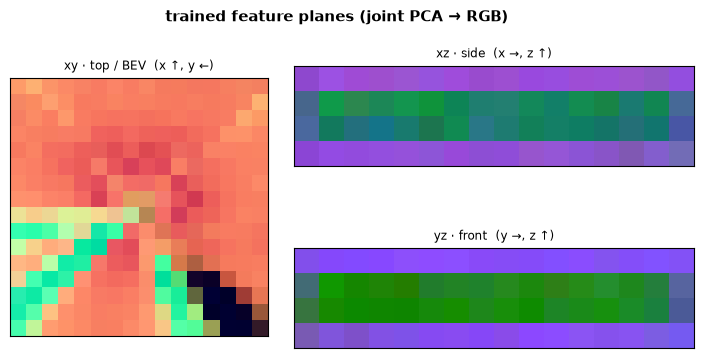

In [13]:
out = exp.predict()
pred = out["voxel_logits"].argmax(1)                       # (B, X, Y, Z) class ids
plotter.labels([("ground truth", scene.label_planes(batch.occupancy)),
                ("prediction", scene.label_planes(pred))],
               title="held-out scene: occupancy collapsed onto the three planes")
plotter.features(out["planes"], title="trained feature planes (joint PCA → RGB)")

### V1 vs V2 (multi-scale) triplane

Train the V2 triplane with the same budget and compare.

lifter          params    time   before    after  corrupted   verdict
bevformer         249k    5.1s    0.008    0.295      0.030   uses geometry
bevformer_v2      265k    6.2s    0.014    0.331      0.028   uses geometry


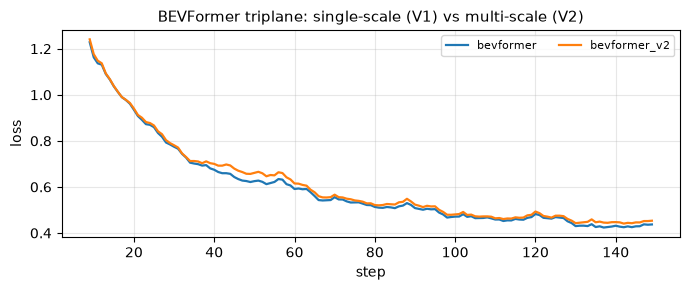

In [14]:
result_v2 = OccupancyExperiment(scene, "bevformer", num_layers=1, num_levels=2).run(steps=150)
result_v2.name = "bevformer_v2"
print(ExperimentResult.header()); print(result.row()); print(result_v2.row())
OccupancyExperiment.plot_losses([result, result_v2], title="BEVFormer triplane: single-scale (V1) vs multi-scale (V2)")

## 8. Negative control: does it really use the cameras?

Same images, same weights - but every camera's extrinsic is rotated by 90° about the vertical axis. A lifter that reads
pixels **through** the calibration now puts every object in the wrong place and its mIoU collapses; a geometry-free
lifter would not notice. (This is the triplane version of the repo's `lifting-verify` check.)

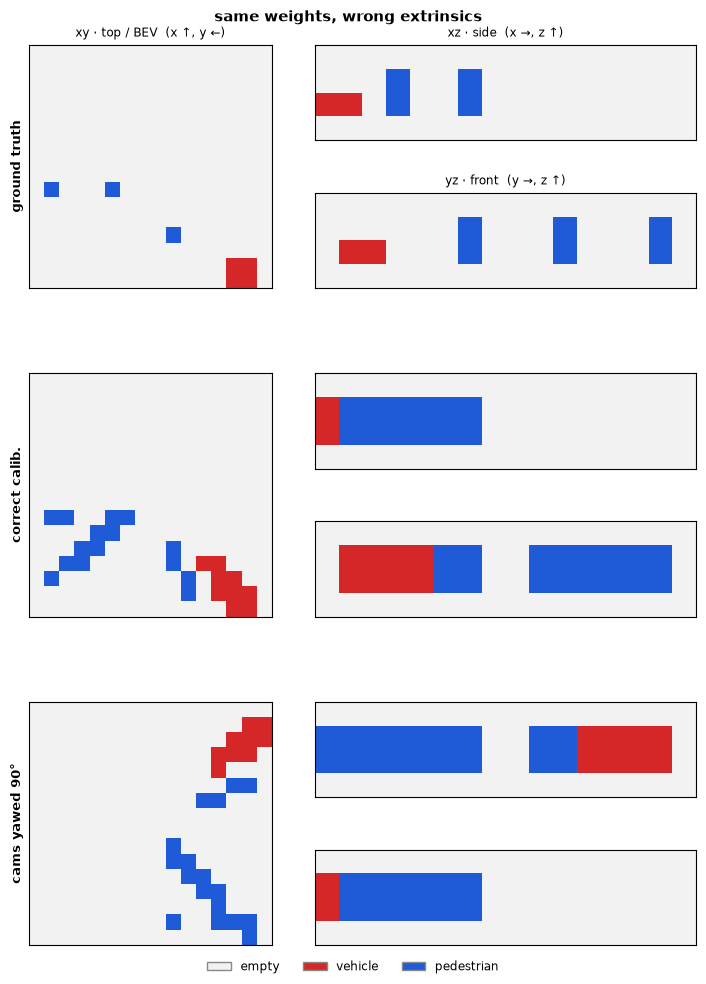

mIoU  correct calibration: 0.295   |   cameras yawed 90°: 0.030   ->  uses geometry ✅


In [15]:
corrupted = exp.predict(corrupted=True)["voxel_logits"].argmax(1)
plotter.labels([("ground truth", scene.label_planes(batch.occupancy)),
                ("correct calib.", scene.label_planes(pred)),
                ("cams yawed 90°", scene.label_planes(corrupted))],
               title="same weights, wrong extrinsics")
print(f"mIoU  correct calibration: {result.miou_after:.3f}   |   cameras yawed 90°: {result.miou_corrupted:.3f}"
      f"   ->  {'uses geometry ✅' if result.uses_geometry else 'does NOT use geometry'}")

## 9. Use it in your own code

```python
from lifting.triplane import TRIPLANE_LIFTERS, build_triplane_model, build_triplane_bev_model

# 1) just the lifter: features (B, N, C, H_l, W_l) per level + Cameras
lifter = TRIPLANE_LIFTERS.build("bevformer", grid=grid, in_channels=64, out_channels=64, num_layers=1)
planes = lifter.lift_planes(features, cameras)   # TPVPlanes(xy, xz, yz)
bev    = lifter(features, cameras)               # (B, 64, X, Y) - drop-in BEV lifter

# 2) 3D semantic occupancy + point queries
model = build_triplane_model("bevformer", grid, num_classes=3, aux_heads=True, num_layers=1)
out = model(images, cameras, points=lidar_xyz)   # planes, voxel_logits, point_logits, aux_logits

# 3) BEV segmentation read off the triplane (same API as lifting.build_bev_model)
bev_model = build_triplane_bev_model("bevformer", grid, num_classes=3, num_layers=1)
```

In [16]:
bev_model = build_triplane_bev_model("bevformer", scene.grid, 3, scene.image_size, scene.num_cameras, channels=16, num_layers=1)
with torch.no_grad():
    logits = bev_model(batch.images, batch.cameras)["logits"]
print("BEV segmentation logits read off the triplane:", tuple(logits.shape))

BEV segmentation logits read off the triplane: (4, 3, 16, 16)


## Recap


* A triplane BEVFormer is three BEVFormer encoders whose queries own anchors along their plane normal.
* All attention modules and the layer are the existing ones; only `PlaneQueryEncoder` (wiring) and `PlaneProjection` are new.
* V2 = the same lifter with `num_levels=2`; the planes then read a feature pyramid.
* No information flows between planes - TPVFormer's cross-view hybrid attention adds exactly that.


**Cheat sheet**

| concept | file |
|---|---|
| BEVFormer layer (unchanged) | `src/lifting/lifters/bevformer/bevformer_layer.py` |
| spatial cross-attention | `src/lifting/attention/spatial_cross_attention.py` |
| anchors per plane | `src/lifting/lifters/tpvformer/tpv_reference_points.py` |
| per-plane encoder | `src/lifting/triplane/plane_query_encoder.py` |
| triplane lifter | `src/lifting/triplane/bevformer_triplane.py` |
| triplane contract | `src/lifting/triplane/base.py` |
| BEV read-off from planes | `src/lifting/triplane/triplane_bev_head.py` |
| occupancy model / factories | `src/lifting/triplane/triplane_occupancy_model.py`, `factory.py` |
| this animation | `src/lifting/triplane/animation/storyboards/bevformer_storyboard.py` |

**Exercises**

1. Use more anchors on the xy plane (`num_anchors=(8, 8, 8)`). Does the BEV mIoU improve?
2. Train with `num_layers=2`. Compare time and mIoU with TPVFormer (notebook 06) at the same depth.
3. Plot the trained `xy` plane next to `BEVFormerLifter`'s BEV map trained on BEV segmentation.

Next: see `00_triplane_overview.ipynb` for all techniques side by side.